# Parte III — Fenômenos Ondulatórios

### Física II — Engenharia Naval, Poli-USP

Este notebook é material de **estudo e revisão visual** sobre ondas mecânicas. Depois de termos
estudado o Movimento Harmônico Simples (MHS) e as oscilações amortecidas/forçadas de um único
grau de liberdade (um corpo oscilando preso a uma mola), damos agora o passo natural seguinte:
e se, em vez de um único corpo oscilando, tivermos uma *cadeia contínua* de osciladores acoplados —
como os pontos de uma corda, ou as partículas da água do mar? A oscilação de um ponto se propaga
para o vizinho, e nasce uma **onda**.

Para quem vai trabalhar com embarcações, isso não é só matemática abstrata: ondas do mar, vibrações
estruturais do casco, cabos e linhas de ancoragem — tudo isso é regido pelas mesmas equações que
vamos deduzir aqui para o caso mais simples (e mais didático) de todos: uma corda esticada.

## Sumário

1. [Conceito de ondas: mecânicas, eletromagnéticas, transversais e longitudinais](#secao1)
2. [Descrição matemática de ondas unidimensionais](#secao2)
    - [2.1 Onda progressiva $y(x,t)=f(x\mp vt)$](#secao2-1)
    - [2.2 Ondas harmônicas: $\lambda$, $T$, $f$](#secao2-2)
    - [2.3 Velocidade de fase](#secao2-3)
    - [2.4 Equação diferencial da onda](#secao2-4)
3. [Equação para cordas vibrantes](#secao3)
    - [3.1 Velocidade de propagação $v=\sqrt{T/\mu}$](#secao3-1)
    - [3.2 Princípio de superposição](#secao3-2)
    - [3.3 Bônus: ondas estacionárias e harmônicos](#secao3-3)


In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.patches import FancyArrowPatch
from IPython.display import HTML
import sympy as sp

# ---- estilo visual consistente para todo o notebook ----
plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "figure.dpi": 100,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "font.size": 11,
    "lines.linewidth": 2.4,
    "axes.prop_cycle": plt.cycler(color=[
        "#1f77b4", "#d62728", "#2ca02c", "#9467bd",
        "#ff7f0e", "#17becf", "#8c564b"
    ]),
})

AZUL   = "#1f77b4"
VERM   = "#d62728"
VERDE  = "#2ca02c"
ROXO   = "#9467bd"
LARANJ = "#ff7f0e"
CIANO  = "#17becf"

plt.rcParams["animation.embed_limit"] = 60  # MB, margem para animações HTML embutidas


<a id="secao1"></a>
## 1. Conceito de ondas

Uma **onda** é uma perturbação que se propaga através do espaço (e, em geral, do tempo),
transportando **energia e momento** sem que, em média, haja transporte de matéria.

### Mecânicas × Eletromagnéticas

| | Ondas **mecânicas** | Ondas **eletromagnéticas** |
|---|---|---|
| Precisam de meio material? | **Sim** — corda, água, ar, casco do navio... | **Não** — se propagam até no vácuo |
| O que oscila? | Partículas do meio (deslocamento, pressão...) | Campos elétrico e magnético |
| Exemplos | Som, ondas do mar, ondas numa corda, abalos sísmicos | Luz, rádio, radar, micro-ondas |

Neste notebook focamos nas ondas **mecânicas**, com a corda vibrante como protagonista — mas a
matemática de propagação ($y = f(x \mp vt)$) é universal, valendo também para luz e rádio.

### Transversais × Longitudinais

- **Transversal**: o meio oscila **perpendicularmente** à direção de propagação da onda.
  Exemplo clássico: uma corda de violão, ou — pensando em mar aberto — a oscilação vertical
  da superfície da água (numa aproximação simplificada; ondas de água de verdade têm
  também uma componente orbital).
- **Longitudinal**: o meio oscila **paralelamente** à direção de propagação.
  Exemplo clássico: uma mola tipo *slinky* sendo comprimida e esticada, ou o som se propagando
  no ar (compressões e rarefações).

Vamos visualizar as duas com uma cadeia de partículas oscilando.


In [2]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6))
n_particles = 41
x0 = np.linspace(0, 10, n_particles)
k_wave, omega = 2*np.pi/2.5, 2*np.pi/1.2

scat_t = axes[0].scatter(x0, np.zeros_like(x0), s=40, c=AZUL, zorder=3)
axes[0].set_xlim(0, 10); axes[0].set_ylim(-1.5, 1.5)
axes[0].set_title("Onda TRANSVERSAL — partículas oscilam ⟂ à propagação")
axes[0].set_xlabel("posição de equilíbrio x"); axes[0].set_ylabel("deslocamento y")
line_t, = axes[0].plot([], [], color=AZUL, alpha=0.5, lw=1.5)

scat_l = axes[1].scatter(x0, np.zeros_like(x0), s=40, c=VERM, zorder=3)
axes[1].set_xlim(0, 10); axes[1].set_ylim(-1, 1)
axes[1].set_yticks([])
axes[1].set_title("Onda LONGITUDINAL (tipo slinky) — partículas oscilam ∥ à propagação")
axes[1].set_xlabel("posição ao longo da mola")

def init():
    line_t.set_data([], [])
    return scat_t, scat_l, line_t

def animate(frame):
    t = frame / 15
    y = 0.8*np.sin(k_wave*x0 - omega*t)
    scat_t.set_offsets(np.column_stack([x0, y]))
    xs_fine = np.linspace(0, 10, 300)
    line_t.set_data(xs_fine, 0.8*np.sin(k_wave*xs_fine - omega*t))

    dx = 0.5*np.sin(k_wave*x0 - omega*t)
    scat_l.set_offsets(np.column_stack([x0 + dx, np.zeros_like(x0)]))
    return scat_t, scat_l, line_t

plt.tight_layout()
anim1 = animation.FuncAnimation(fig, animate, init_func=init, frames=90, interval=50, blit=True)
plt.close(fig)
HTML(anim1.to_jshtml())


C:\Users\PedroOliveira\AppData\Local\Temp\ipykernel_26236\3141870286.py:33: UserWarning: Glyph 10178 (\N{PERPENDICULAR}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


C:\Users\PedroOliveira\AppData\Local\Temp\ipykernel_26236\3141870286.py:36: UserWarning: Glyph 10178 (\N{PERPENDICULAR}) missing from font(s) DejaVu Sans.
  HTML(anim1.to_jshtml())


> **Intuição física:** repare que, na onda longitudinal, as partículas se agrupam (compressão)
> e se espalham (rarefação) periodicamente — é exatamente assim que o som viaja no ar e como
> um pulso de compressão viaja ao longo de uma amarra ou cabo esticado axialmente. Já a onda
> transversal é a "cara" que associamos a ondas na água e em cordas de instrumentos.


<a id="secao2"></a>
## 2. Descrição matemática de ondas unidimensionais

<a id="secao2-1"></a>
### 2.1 Função de onda progressiva — $y(x,t) = f(x \mp vt)$

A ideia central: uma onda que se propaga **sem mudar de forma** com velocidade $v$ é descrita por
uma função de **duas variáveis que colapsam em uma só combinação**:

$$y(x,t) = f(x - vt) \quad \text{(onda se movendo no sentido } +x\text{)}$$
$$y(x,t) = f(x + vt) \quad \text{(onda se movendo no sentido } -x\text{)}$$

O argumento $u = x - vt$ é chamado de **fase** da onda. Se fixarmos $u$ (ou seja, "andarmos
junto" com um ponto específico do perfil, como uma crista), obtemos $x - vt = \text{const}
\Rightarrow dx/dt = v$: a crista se move com velocidade $v$. É por isso que o formato do pulso
não muda — toda a função $f$ está sendo transladada rigidamente.


In [3]:
def pulso_gaussiano(u, largura=0.6):
    return np.exp(-(u**2) / (2*largura**2))

x = np.linspace(-2, 12, 600)
v = 3.0
tempos = np.linspace(0, 3, 90)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.set_xlim(x.min(), x.max()); ax.set_ylim(-0.2, 1.3)
ax.set_xlabel("x"); ax.set_ylabel("y(x,t)")
ax.set_title("Pulso gaussiano $y(x,t)=f(x-vt)$ propagando-se sem deformar")
linha, = ax.plot([], [], color=AZUL)
ponto_crista, = ax.plot([], [], "o", color=VERM, ms=10, zorder=5)
texto = ax.text(0.02, 0.92, "", transform=ax.transAxes, fontsize=11)

def init2():
    linha.set_data([], [])
    ponto_crista.set_data([], [])
    texto.set_text("")
    return linha, ponto_crista, texto

def animate2(i):
    t = tempos[i]
    y = pulso_gaussiano(x - v*t)
    linha.set_data(x, y)
    x_crista = v*t
    ponto_crista.set_data([x_crista], [pulso_gaussiano(0)])
    texto.set_text(f"t = {t:.2f} s   |   crista em x = vt = {x_crista:.2f} m")
    return linha, ponto_crista, texto

plt.tight_layout()
anim2 = animation.FuncAnimation(fig, animate2, init_func=init2, frames=len(tempos),
                                 interval=50, blit=True)
plt.close(fig)
HTML(anim2.to_jshtml())


> **Intuição física:** pense num pulso criado chacoalhando uma ponta de corda (ou uma onda
> solitária se afastando de um barco). O formato (a "assinatura" do pulso) não muda — só sua
> *posição* muda com o tempo. É essa invariância de forma que caracteriza a propagação ondulatória
> não-dispersiva.

<a id="secao2-2"></a>
### 2.2 Caso especial: ondas harmônicas

O caso mais importante de função de onda é a **onda harmônica** (senoidal):

$$y(x,t) = A\sin(kx - \omega t)$$

onde:

- $A$ = amplitude;
- $k = \dfrac{2\pi}{\lambda}$ = **número de onda** (rad/m), com $\lambda$ o **comprimento de onda**;
- $\omega = \dfrac{2\pi}{T} = 2\pi f$ = **frequência angular** (rad/s), com $T$ o **período** e
  $f$ a **frequência**.

$\lambda$ é "visto" congelando o tempo e observando o padrão espacial; $T$ é "visto" congelando a
posição e observando a evolução temporal em um ponto fixo. Vamos ilustrar os dois lado a lado.


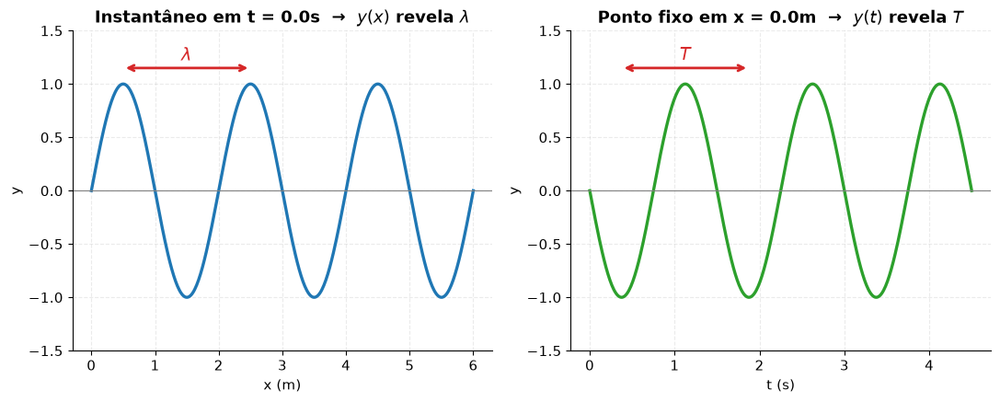

λ = 2.0 m, T = 1.5 s  →  f = 1/T = 0.667 Hz,  k = 2π/λ = 3.142 rad/m,  ω = 2π/T = 4.189 rad/s


In [4]:
A, lam, T = 1.0, 2.0, 1.5
k = 2*np.pi/lam
omega = 2*np.pi/T

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

# --- esquerda: y(x) em t fixo -> mostra lambda ---
t_fixo = 0.0
xs = np.linspace(0, 3*lam, 400)
ys = A*np.sin(k*xs - omega*t_fixo)
ax1.plot(xs, ys, color=AZUL)
ax1.axhline(0, color="gray", lw=0.8)
# marca um comprimento de onda entre dois zeros ascendentes
x_a, x_b = lam/4, lam/4 + lam
ax1.annotate("", xy=(x_b, 1.15), xytext=(x_a, 1.15),
             arrowprops=dict(arrowstyle="<->", color=VERM, lw=2))
ax1.text((x_a+x_b)/2, 1.22, r"$\lambda$", color=VERM, ha="center", fontsize=14)
ax1.set_title(f"Instantâneo em t = {t_fixo:.1f}s  →  $y(x)$ revela $\\lambda$")
ax1.set_xlabel("x (m)"); ax1.set_ylabel("y")
ax1.set_ylim(-1.5, 1.5)

# --- direita: y(t) em x fixo -> mostra T ---
x_fixo = 0.0
ts = np.linspace(0, 3*T, 400)
yt = A*np.sin(k*x_fixo - omega*ts)
ax2.plot(ts, yt, color=VERDE)
ax2.axhline(0, color="gray", lw=0.8)
t_a, t_b = T/4, T/4 + T
ax2.annotate("", xy=(t_b, 1.15), xytext=(t_a, 1.15),
             arrowprops=dict(arrowstyle="<->", color=VERM, lw=2))
ax2.text((t_a+t_b)/2, 1.22, r"$T$", color=VERM, ha="center", fontsize=14)
ax2.set_title(f"Ponto fixo em x = {x_fixo:.1f}m  →  $y(t)$ revela $T$")
ax2.set_xlabel("t (s)"); ax2.set_ylabel("y")
ax2.set_ylim(-1.5, 1.5)

plt.tight_layout()
plt.show()

print(f"λ = {lam} m, T = {T} s  →  f = 1/T = {1/T:.3f} Hz,  k = 2π/λ = {k:.3f} rad/m,  "
      f"ω = 2π/T = {omega:.3f} rad/s")


<a id="secao2-3"></a>
### 2.3 Velocidade de fase

Para a onda harmônica monocromática, a velocidade com que um ponto de fase constante (por
exemplo, uma crista) se desloca é a **velocidade de fase**:

$$v = \frac{\omega}{k} = \lambda f$$

Vamos animar a onda e marcar explicitamente uma crista se movendo com essa velocidade, com uma
seta indicando sentido e módulo de $v$.


In [5]:
A, lam, T = 1.0, 2.0, 1.0
k = 2*np.pi/lam
omega = 2*np.pi/T
v_fase = omega/k
print(f"v = ω/k = λf = {v_fase:.2f} m/s")

xs = np.linspace(0, 10, 500)
fig, ax = plt.subplots(figsize=(9, 4.3))
ax.set_xlim(0, 10); ax.set_ylim(-1.6, 1.8)
ax.set_xlabel("x (m)"); ax.set_ylabel("y")
ax.set_title(r"Onda harmônica $y=A\sin(kx-\omega t)$ — crista move-se com $v=\omega/k$")
linha_h, = ax.plot([], [], color=AZUL)
crista_pt, = ax.plot([], [], "o", color=VERM, ms=10, zorder=5)
seta = [None]
texto_v = ax.text(0.02, 0.92, "", transform=ax.transAxes)

def init3():
    linha_h.set_data([], [])
    crista_pt.set_data([], [])
    texto_v.set_text("")
    return linha_h, crista_pt, texto_v

def animate3(frame):
    t = frame * 0.03
    y = A*np.sin(k*xs - omega*t)
    linha_h.set_data(xs, y)
    # posicao da crista mais proxima que comeca em x=lam/4 (fase 0) e anda com v
    x_crista = (lam/4 + v_fase*t) % 10
    crista_pt.set_data([x_crista], [A])
    if seta[0] is not None:
        seta[0].remove()
    seta[0] = ax.annotate("", xy=(min(x_crista+1.2, 9.8), A+0.35), xytext=(x_crista, A+0.35),
                           arrowprops=dict(arrowstyle="->", color=VERDE, lw=2.5))
    texto_v.set_text(f"t = {t:.2f} s   v = ω/k = {v_fase:.2f} m/s")
    return linha_h, crista_pt, texto_v, seta[0]

plt.tight_layout()
anim3 = animation.FuncAnimation(fig, animate3, init_func=init3, frames=140, interval=40, blit=False)
plt.close(fig)
HTML(anim3.to_jshtml())


v = ω/k = λf = 2.00 m/s


> **Intuição física:** a velocidade de fase não é a velocidade de nenhuma partícula do meio
> (cada ponto da corda só sobe e desce!) — é a velocidade com que o *padrão* se desloca. É o
> análogo de uma onda de "Mexicana" (ola) em um estádio: cada torcedor só levanta e abaixa os
> braços, mas o padrão percorre as arquibancadas com uma velocidade própria, geralmente bem
> maior que o movimento de qualquer pessoa individualmente.

<a id="secao2-4"></a>
### 2.4 Equação diferencial parcial da onda

Toda onda que se propaga sem deformar com velocidade $v$ (incluindo $f(x\mp vt)$ genérico) satisfaz
a **equação de onda unidimensional**:

$$\frac{\partial^2 y}{\partial x^2} = \frac{1}{v^2}\frac{\partial^2 y}{\partial t^2}$$

Vamos verificar simbolicamente, com `sympy`, que a onda harmônica $y = A\sin(kx-\omega t)$ é de
fato solução dessa equação, desde que $v = \omega/k$.


In [6]:
x_s, t_s, A_s, k_s, w_s, v_s = sp.symbols('x t A k omega v', real=True, positive=True)

y = A_s*sp.sin(k_s*x_s - w_s*t_s)
display(sp.Eq(sp.Symbol('y(x,t)'), y))

d2y_dx2 = sp.diff(y, x_s, 2)
d2y_dt2 = sp.diff(y, t_s, 2)

print("∂²y/∂x² =")
display(d2y_dx2)
print("∂²y/∂t² =")
display(d2y_dt2)

# lado esquerdo - lado direito da equacao de onda, substituindo v = omega/k
lhs = d2y_dx2
rhs = (1/v_s**2) * d2y_dt2
residuo = sp.simplify((lhs - rhs).subs(v_s, w_s/k_s))

print("\nResíduo (∂²y/∂x² − (1/v²)∂²y/∂t²) após substituir v = ω/k :")
display(sp.simplify(residuo))
print("\n→ resíduo é identicamente nulo: a onda harmônica satisfaz a equação de onda",
      "quando v = ω/k. ✔" if residuo == 0 else "✘ (verificar)")


Eq(y(x,t), A*sin(k*x - omega*t))

∂²y/∂x² =


-A*k**2*sin(k*x - omega*t)

∂²y/∂t² =


-A*omega**2*sin(k*x - omega*t)


Resíduo (∂²y/∂x² − (1/v²)∂²y/∂t²) após substituir v = ω/k :


0


→ resíduo é identicamente nulo: a onda harmônica satisfaz a equação de onda quando v = ω/k. ✔


> **Intuição física:** a equação de onda diz, em palavras, que a *curvatura espacial* do
> perfil ($\partial^2 y/\partial x^2$) é proporcional à *aceleração* de cada ponto do meio
> ($\partial^2 y/\partial t^2$). Isso é exatamente a 2ª Lei de Newton aplicada a um elementinho
> de corda: quanto mais "curvado" ele está em relação aos vizinhos, maior a força restauradora
> (e portanto a aceleração) que o puxa de volta.


<a id="secao3"></a>
## 3. Equação para cordas vibrantes

<a id="secao3-1"></a>
### 3.1 Velocidade de propagação $v = \sqrt{T/\mu}$

Aplicando a 2ª Lei de Newton a um elemento infinitesimal de uma corda esticada com **tração** $T$
(força, em N) e **densidade linear de massa** $\mu$ (kg/m), obtém-se a velocidade de propagação
de ondas transversais na corda:

$$v = \sqrt{\frac{T}{\mu}}$$

Quanto mais esticada a corda (maior $T$), mais rápido o pulso se propaga; quanto mais "pesada"
por unidade de comprimento (maior $\mu$), mais devagar. Pense num cabo de amarração: um cabo mais
tensionado transmite perturbações mais rapidamente do que um cabo frouxo.


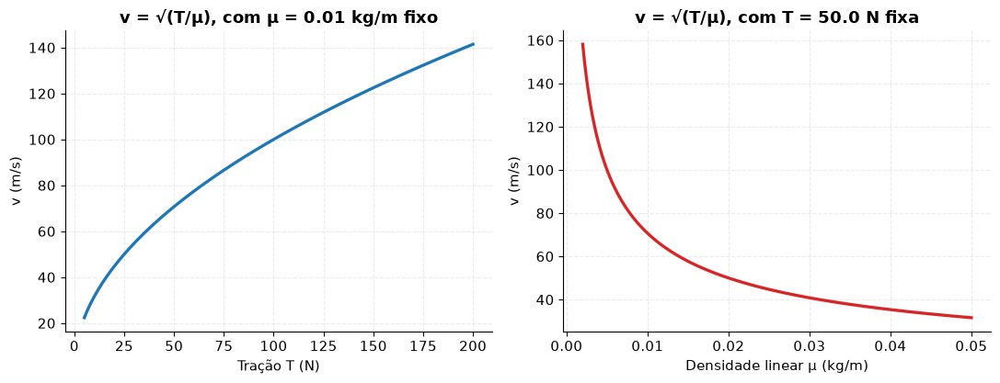

In [7]:
mu_fixo = 0.01   # kg/m
T_fixo = 50.0    # N

T_range = np.linspace(5, 200, 200)
mu_range = np.linspace(0.002, 0.05, 200)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.3))

v_vs_T = np.sqrt(T_range/mu_fixo)
ax1.plot(T_range, v_vs_T, color=AZUL)
ax1.set_xlabel("Tração T (N)"); ax1.set_ylabel("v (m/s)")
ax1.set_title(f"v = √(T/μ), com μ = {mu_fixo} kg/m fixo")

v_vs_mu = np.sqrt(T_fixo/mu_range)
ax2.plot(mu_range, v_vs_mu, color=VERM)
ax2.set_xlabel("Densidade linear μ (kg/m)"); ax2.set_ylabel("v (m/s)")
ax2.set_title(f"v = √(T/μ), com T = {T_fixo} N fixa")

plt.tight_layout()
plt.show()


> **Intuição física:** note o comportamento de raiz quadrada — para **dobrar** a velocidade
> de propagação só aumentando a tração, é preciso **quadruplicar** a força de tração. Isso é
> relevante, por exemplo, ao projetar cabos ou linhas de ancoragem onde se deseja controlar a
> velocidade com que perturbações (impactos, solavancos) se propagam ao longo do cabo.

<a id="secao3-2"></a>
### 3.2 Princípio de superposição

Quando duas ondas se encontram na mesma corda, o deslocamento resultante é simplesmente a **soma**
dos deslocamentos de cada onda, como se a outra não estivesse lá:

$$y_{\text{total}}(x,t) = y_1(x,t) + y_2(x,t)$$

Isso é o **princípio de superposição**, válido para meios lineares (pequenas amplitudes). Um
resultado belíssimo: dois pulsos podem se superpor, interferir (construtiva ou destrutivamente),
e depois **continuar cada um seu caminho, inalterados**, como se nada tivesse acontecido.

Vamos animar dois casos: pulsos de **mesmo sinal** (interferência construtiva) e de **sinais
opostos** (interferência destrutiva, com cancelamento momentâneo).


In [8]:
def pulso(x, x0, largura=0.5, sinal=1.0):
    return sinal*np.exp(-((x-x0)**2)/(2*largura**2))

L = 20.0
xs = np.linspace(0, L, 600)
v = 4.0
t_max = 3.0
frames = 120
tempos = np.linspace(0, t_max, frames)

def montar_animacao_superposicao(sinal2, titulo):
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.set_xlim(0, L); ax.set_ylim(-2.3, 2.3)
    ax.set_xlabel("x (m)"); ax.set_ylabel("y")
    ax.set_title(titulo)
    l1, = ax.plot([], [], "--", color=AZUL, lw=1.6, alpha=0.7, label="onda 1 (→)")
    l2, = ax.plot([], [], "--", color=VERM, lw=1.6, alpha=0.7, label="onda 2 (←)")
    ltot, = ax.plot([], [], color=VERDE, lw=3, label="soma (corda real)")
    ax.legend(loc="upper right", fontsize=9)

    def init():
        l1.set_data([], []); l2.set_data([], []); ltot.set_data([], [])
        return l1, l2, ltot

    def animate(i):
        t = tempos[i]
        y1 = pulso(xs, 4 + v*t, sinal=1.0)
        y2 = pulso(xs, L - 4 - v*t, sinal=sinal2)
        l1.set_data(xs, y1)
        l2.set_data(xs, y2)
        ltot.set_data(xs, y1 + y2)
        return l1, l2, ltot

    plt.tight_layout()
    anim = animation.FuncAnimation(fig, animate, init_func=init, frames=frames,
                                    interval=45, blit=True)
    plt.close(fig)
    return anim

anim_construtiva = montar_animacao_superposicao(
    +1.0, "Superposição de pulsos de MESMO sinal — interferência construtiva")
HTML(anim_construtiva.to_jshtml())


In [9]:
anim_destrutiva = montar_animacao_superposicao(
    -1.0, "Superposição de pulsos de sinais OPOSTOS — interferência destrutiva")
HTML(anim_destrutiva.to_jshtml())


> **Intuição física:** no instante do cruzamento, a corda pode parecer quase "lisa" (no caso
> destrutivo) ou ter o dobro da amplitude (no caso construtivo) — mas isso é só uma fotografia
> instantânea. Assim que os pulsos se afastam, cada um retoma exatamente sua forma e amplitude
> originais, como se a superposição nunca tivesse ocorrido. Isso só vale em regime **linear**
> (pequenas amplitudes); ondas de água muito grandes podem interagir de forma não-linear e deixar
> "marcas" permanentes umas nas outras (ex.: ondas rogue/"freak waves" no mar).

<a id="secao3-3"></a>
### 3.3 Bônus: ondas estacionárias e harmônicos

Uma aplicação direta da superposição: numa corda **presa nas duas extremidades** (como uma corda
de violão, ou um cabo esticado entre dois pontos fixos de um navio), ondas progressivas que vão e
voltam, refletindo nas extremidades, se superpõem e formam **ondas estacionárias**:

$$y_n(x,t) = \underbrace{2A\sin(k_n x)}_{\text{perfil espacial fixo}} \cos(\omega_n t),
\qquad k_n = \frac{n\pi}{L}, \quad n=1,2,3,\dots$$

Essa é exatamente a soma de uma onda progressiva para a direita com uma para a esquerda, de mesma
amplitude e frequência. Os pontos onde $\sin(k_n x)=0$ sempre (chamados **nós**) não se movem
nunca; os pontos de máxima amplitude são os **ventres**.


In [10]:
L = 10.0
xs = np.linspace(0, L, 400)
harmonicos = [1, 2, 3]
cores_h = [AZUL, VERM, VERDE]
frames = 100
tempos = np.linspace(0, 2, frames)

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
linhas = []
for ax, n, cor in zip(axes, harmonicos, cores_h):
    ax.set_xlim(0, L); ax.set_ylim(-1.3, 1.3)
    ax.set_title(f"n = {n}  (harmônico {n})")
    ax.set_xlabel("x (m)")
    ax.axhline(0, color="gray", lw=0.7)
    linha, = ax.plot([], [], color=cor, lw=3)
    # marca nos (pontos fixos)
    k_n = n*np.pi/L
    nos_x = [j*np.pi/k_n for j in range(n+1)]
    ax.plot(nos_x, [0]*len(nos_x), "o", color="black", ms=6, zorder=5, label="nós")
    ax.legend(loc="upper right", fontsize=8)
    linhas.append(linha)
axes[0].set_ylabel("y")

def init4():
    for linha in linhas:
        linha.set_data([], [])
    return linhas

def animate4(i):
    t = tempos[i]
    for linha, n in zip(linhas, harmonicos):
        k_n = n*np.pi/L
        omega_n = k_n * 3.0   # v = 3 m/s fixo so para visualizacao
        y = np.sin(k_n*xs) * np.cos(omega_n*t)
        linha.set_data(xs, y)
    return linhas

plt.tight_layout()
anim4 = animation.FuncAnimation(fig, animate4, init_func=init4, frames=frames,
                                 interval=50, blit=True)
plt.close(fig)
HTML(anim4.to_jshtml())


> **Intuição física:** repare que os **nós** (pontos pretos) nunca se movem — são posições de
> interferência destrutiva permanente entre a onda que vai e a que volta. Entre dois nós
> consecutivos, a corda inteira sobe e desce em fase, como um único "pulmão" oscilando — esse é
> o **ventre**. O número de harmônico $n$ é também o número de "lóbulos" (meio-comprimentos de
> onda) que cabem entre as extremidades fixas: $L = n\lambda_n/2$.

---

## Resumo desta seção

| Conceito | Expressão-chave |
|---|---|
| Onda progressiva | $y(x,t)=f(x\mp vt)$ |
| Onda harmônica | $y=A\sin(kx-\omega t)$, $k=2\pi/\lambda$, $\omega=2\pi/T=2\pi f$ |
| Velocidade de fase | $v=\omega/k=\lambda f$ |
| Equação de onda | $\partial^2y/\partial x^2=(1/v^2)\,\partial^2y/\partial t^2$ |
| Velocidade numa corda | $v=\sqrt{T/\mu}$ |
| Superposição | $y_{\text{total}}=y_1+y_2$ (regime linear) |
| Onda estacionária | $y_n=2A\sin(k_nx)\cos(\omega_nt)$, $k_n=n\pi/L$ |

Próximo passo natural do curso: ondas sonoras tridimensionais, intensidade e o efeito Doppler —
mas a espinha dorsal matemática (progressiva, harmônica, equação de onda) permanece a mesma que
vimos aqui.
